<a href="https://colab.research.google.com/github/paurnavi25/SCI-10-RAG-Development/blob/main/10_SCIENCE_RAG.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install pymupdf

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25.8/25.8 MB 54.2 MB/s eta 0:00:00


In [2]:
import os
os.listdir()

['.config', 'jesc101.pdf', 'sample_data']

In [3]:
import pymupdf
pdf_path = "jesc101.pdf"
doc = pymupdf.open(pdf_path)
print("Number of pages:", len(doc))

Number of pages: 16


In [4]:
for page_number in range(2):
    page = doc[page_number]
    text = page.get_text()
    print("\n" + "=" * 80)
    print("PAGE", page_number + 1)
    print("=" * 80)

    print(text[:3000])

    print(
        f"Page {page_number + 1}: "
        f"text={len(page.get_text())} characters, "
        f"images={len(page.get_images(full=True))}"
    )


PAGE 1
Chemical Reactions
and Equations
1
CHAPTER
C
onsider the following situations of daily life and think what happens
when –
n
milk is left at room temperature during summers.
n
an iron tawa/pan/nail is left exposed to humid atmosphere.
n
grapes get fermented.
n
food is cooked.
n
food gets digested in our body.
n
we respire.
In all the above situations, the nature and the identity of the initial
substance have somewhat changed. We have already learnt about physical
and chemical changes of matter in our previous classes. Whenever a chemical
change occurs, we can say that a chemical reaction has taken place.
You may perhaps be wondering as to what is actually meant by a
chemical reaction. How do we come to know that a chemical reaction
has taken place? Let us perform some activities to find the answer to
these questions.
Figure 1.1
Burning of a magnesium ribbon in air and collection of magnesium
oxide in a watch-glass
Activity 1.1
Activity 1.1
Activity 1.1
Activity 1.1
Activity 1.1


In [6]:
import fitz

page = doc[1]
pix = page.get_pixmap(matrix=fitz.Matrix(1.5, 1.5))
pix.save("page_2.png")

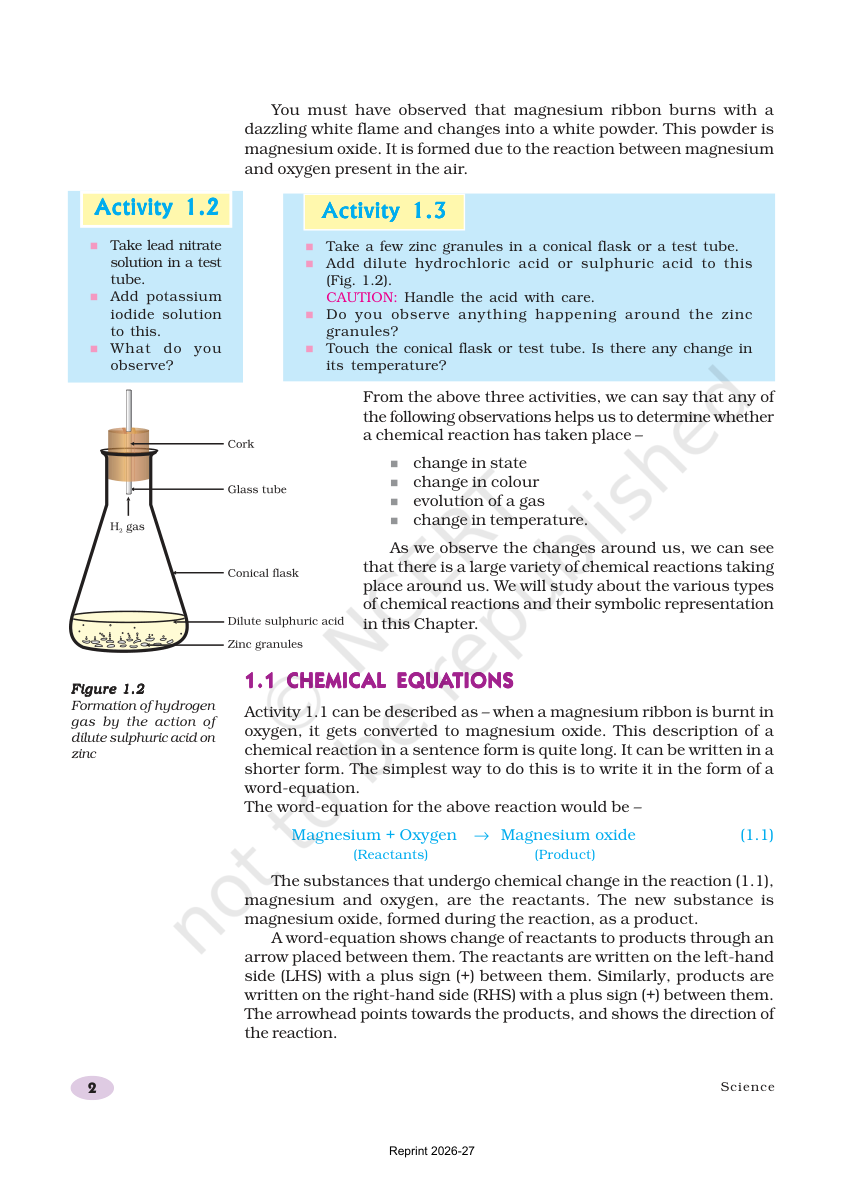

In [7]:
from IPython.display import display
from PIL import Image

display(Image.open("page_2.png"))

In [8]:
page = doc[1]

blocks = page.get_text("blocks")

for i, block in enumerate(blocks):
    print("\n" + "=" * 60)
    print("BLOCK", i)
    print("=" * 60)
    print(block[4])


BLOCK 0
Science
2


BLOCK 1
Activity 1.2
Activity 1.2
Activity 1.2
Activity 1.2
Activity 1.2


BLOCK 2
Figure 1.2
Figure 1.2
Figure 1.2
Figure 1.2
Figure 1.2
Formation of hydrogen
gas by the action of
dilute sulphuric acid on
zinc


BLOCK 3
From the above three activities, we can say that any of
the following observations helps us to determine whether
a chemical reaction has taken place –


BLOCK 4
n
change in state


BLOCK 5
n
change in colour


BLOCK 6
n
evolution of a gas


BLOCK 7
n
change in temperature.


BLOCK 8
As we observe the changes around us, we can see
that there is a large variety of chemical reactions taking
place around us. We will study about the various types
of chemical reactions and their symbolic representation
in this Chapter.


BLOCK 9
Activity 1.3
Activity 1.3
Activity 1.3
Activity 1.3
Activity 1.3


BLOCK 10
n
Take a few zinc granules in a conical flask or a test tube.


BLOCK 11
n
Add dilute hydrochloric acid or sulphuric acid to this
(Fig. 1.2).
CAUTION: Ha

In [9]:
page = doc[1]
for i, block in enumerate(page.get_text("blocks")):
    x0, y0, x1, y1, text, *_ = block

    clean = text.strip()

    if "Activity 1.2" in clean or "1.1 CHEMIC" in clean:
        print(
            f"BLOCK {i}: "
            f"{clean!r} | "
            f"({x0:.2f}, {y0:.2f}, {x1:.2f}, {y1:.2f})"
        )

BLOCK 1: 'Activity 1.2\nActivity 1.2\nActivity 1.2\nActivity 1.2\nActivity 1.2' | (62.67, 131.05, 146.36, 145.47)
BLOCK 17: '1.1 CHEMIC\n1.1 CHEMIC\n1.1 CHEMIC\n1.1 CHEMIC\n1.1 CHEMICAL EQUA\nAL EQUA\nAL EQUA\nAL EQUA\nAL EQUATIONS\nTIONS\nTIONS\nTIONS\nTIONS' | (162.75, 447.06, 342.45, 461.48)


In [10]:
page = doc[1]
for block_no, block in enumerate(page.get_text("dict")["blocks"]):
    if "lines" not in block:
        continue
    for line_no, line in enumerate(block["lines"]):
        for span_no, span in enumerate(line["spans"]):
            text = span["text"].strip()
            if text:
                print(
                    f"Block {block_no}, "
                    f"Line {line_no}, "
                    f"Span {span_no} | "
                    f"{text!r} | "
                    f"size={span['size']:.1f} | "
                    f"bbox={span['bbox']}"
                )

Block 0, Line 0, Span 0 | 'Science' | size=8.5 | bbox=(480.4800109863281, 720.801025390625, 516.4851684570312, 729.301025390625)
Block 0, Line 1, Span 0 | '2' | size=8.5 | bbox=(58.31999969482422, 721.177001953125, 64.49949645996094, 730.467529296875)
Block 1, Line 0, Span 0 | 'Activity 1.2' | size=14.0 | bbox=(63.089996337890625, 131.4666748046875, 146.36199951171875, 145.4666748046875)
Block 1, Line 1, Span 0 | 'Activity 1.2' | size=14.0 | bbox=(62.66999816894531, 131.4666748046875, 145.94200134277344, 145.4666748046875)
Block 1, Line 2, Span 0 | 'Activity 1.2' | size=14.0 | bbox=(63.089996337890625, 131.04669189453125, 146.36199951171875, 145.04669189453125)
Block 1, Line 3, Span 0 | 'Activity 1.2' | size=14.0 | bbox=(62.66999816894531, 131.04669189453125, 145.94200134277344, 145.04669189453125)
Block 1, Line 4, Span 0 | 'Activity 1.2' | size=14.0 | bbox=(62.87999725341797, 131.2567138671875, 146.15200805664062, 145.2567138671875)
Block 2, Line 0, Span 0 | 'Figure 1.2' | size=9.0 | 

In [11]:
import re

def clean_duplicate_lines(text):
    """Removes exact duplicate consecutive lines often caused by PDF drop shadows."""
    lines = [line.strip() for line in text.split('\n') if line.strip()]
    seen = set()
    unique_lines = []
    for line in lines:
        if line not in seen:
            unique_lines.append(line)
            seen.add(line)
    return "\n".join(unique_lines)

# Test cleaning on Block 1
sample_block_text = "Activity 1.2\nActivity 1.2\nActivity 1.2\nActivity 1.2"
print("Original Block:\n", sample_block_text)
print("\nCleaned Block:\n", clean_duplicate_lines(sample_block_text))

Original Block:
 Activity 1.2
Activity 1.2
Activity 1.2
Activity 1.2

Cleaned Block:
 Activity 1.2


In [12]:
# Let's parse the whole PDF into structured, clean chunks.
chunks = []

for page_idx in range(len(doc)):
    page = doc[page_idx]
    blocks = page.get_text("blocks")

    for block_idx, block in enumerate(blocks):
        text = block[4].strip()
        if not text:
            continue

        cleaned_text = clean_duplicate_lines(text)

        # Skip header/footer noise like Page numbers or 'Reprint'
        if re.match(r'^\d+$', cleaned_text) or "Reprint" in cleaned_text:
            continue

        chunks.append({
            "page": page_idx + 1,
            "block_id": block_idx,
            "text": cleaned_text
        })

print(f"Created {len(chunks)} cleaned textbook chunks!")
print("\nExample Chunk 5:")
print(f"Page {chunks[5]['page']}: {chunks[5]['text']}")

Created 325 cleaned textbook chunks!

Example Chunk 5:
Page 1: n
an iron tawa/pan/nail is left exposed to humid atmosphere.


In [13]:
!pip install sentence-transformers

In [14]:
from sentence_transformers import SentenceTransformer
import numpy as np

# Load a small, fast embedding model perfect for Colab CPU
embedder = SentenceTransformer("all-MiniLM-L6-v2")

# Embed our clean chunks
corpus_texts = [chunk['text'] for chunk in chunks]
corpus_embeddings = embedder.encode(corpus_texts, convert_to_tensor=True)

print("Textbook embedded successfully!")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Textbook embedded successfully!


In [15]:
def search_textbook(query, top_k=3):
    query_embedding = embedder.encode(query, convert_to_tensor=True)

    # Calculate cosine similarity
    from sentence_transformers import util
    cos_scores = util.cos_sim(query_embedding, corpus_embeddings)[0]

    # Get top_k results
    top_results = np.argsort(cos_scores.cpu().numpy())[-top_k:][::-1]

    print(f"Query: '{query}'\n")
    for idx in top_results:
        score = cos_scores[idx].item()
        chunk = chunks[idx]
        print(f"[Score: {score:.3f} | Page {chunk['page']}]")
        print(chunk['text'])
        print("-" * 50)

# Test a query kid might ask about Chapter 1 experiments!
search_textbook("What happens when we burn magnesium ribbon?", top_k=2)

Query: 'What happens when we burn magnesium ribbon?'

[Score: 0.802 | Page 6]
1.
Why should a magnesium ribbon be cleaned before burning in air?
--------------------------------------------------
[Score: 0.749 | Page 2]
You must have observed that magnesium ribbon burns with a
dazzling white flame and changes into a white powder. This powder is
magnesium oxide. It is formed due to the reaction between magnesium
and oxygen present in the air.
--------------------------------------------------


In [18]:
from google import genai
from google.colab import userdata
import os

try:
    # Retrieve key from Colab Secrets
    api_key = userdata.get('GOOGLE_API_KEY')
    client = genai.Client(api_key=api_key)
    print("Gemini API client initialized successfully!")
except Exception as e:
    print("🔑 ACTION REQUIRED: Please add your 'GOOGLE_API_KEY' to the Colab Secrets tab on the left sidebar and enable Notebook Access.")
    print(f"\nError Details: {e}")

🔑 ACTION REQUIRED: Please add your 'GOOGLE_API_KEY' to the Colab Secrets tab on the left sidebar and enable Notebook Access.

Error Details: Secret GOOGLE_API_KEY does not exist.


In [19]:
def teach_kid(query):
    # Ensure client is defined in global scope before running
    if 'client' not in globals():
        print("❌ ERROR: 'client' is not defined. Please add your GOOGLE_API_KEY to your Colab Secrets and run the initialization cell first.")
        return

    # 1. Retrieve relevant chunks
    query_embedding = embedder.encode(query, convert_to_tensor=True)
    from sentence_transformers import util
    cos_scores = util.cos_sim(query_embedding, corpus_embeddings)[0]
    top_results = np.argsort(cos_scores.cpu().numpy())[-3:][::-1]

    retrieved_context = ""
    for idx in top_results:
        retrieved_context += f"[Source Page {chunks[idx]['page']}]:\n{chunks[idx]['text']}\n\n"

    # 2. Construct the teacher prompt
    prompt = f"""You are a friendly, encouraging science teacher helping a middle school student understand chemistry.
Using ONLY the textbook context provided below, answer the student's question in a simple, easy-to-understand way.
Use analogies if helpful, and keep it engaging!

Context from Textbook:
{retrieved_context}

Student's Question: {query}
Teacher's Explanation:"""

    # 3. Generate response using Gemini
    try:
        response = client.models.generate_content(
            model='gemini-2.5-flash-lite',
            contents=prompt
        )
        print(f"--- Teacher's Answer to: '{query}' ---\n")
        print(response.text)
    except Exception as e:
        print("❌ Generation failed. Make sure your API key is active and configured correctly.")
        print("Details:", e)

# Let's test our complete RAG chain!
teach_kid("Why do we need to rub the magnesium ribbon with sandpaper before burning it?")

❌ ERROR: 'client' is not defined. Please add your GOOGLE_API_KEY to your Colab Secrets and run the initialization cell first.


### Stage 2: Robust Structure-Aware Cleaning and Quality Reporting
We will now write a pipeline that:
1. Merges lonely list markers (`n` or bullet characters) with their corresponding descriptive text blocks.
2. Generates an **Extraction Quality Report** flagging potentially problematic pages (e.g., extremely low text count, high ratio of duplicate lines, or zero images).

In [23]:
import re
import json

def clean_text_block(text):
    """Removes exact duplicate consecutive lines often caused by PDF drop shadows and cleans bullet markers."""
    # 1. Deduplicate lines caused by drop shadows
    lines = [line.strip() for line in text.split('\n') if line.strip()]
    seen = set()
    unique_lines = []
    for line in lines:
        if line not in seen:
            unique_lines.append(line)
            seen.add(line)

    # 2. Join lines back together
    cleaned_text = "\n".join(unique_lines)

    # 3. Clean up the 'n' bullet characters at the start of lines/paragraphs
    # In this font, a lowercase 'n' followed by a newline or space at the beginning of list items represents a bullet point.
    cleaned_text = re.sub(r'^(n\s*\n|n\s+)', '• ', cleaned_text)
    cleaned_text = re.sub(r'\n(n\s*\n|n\s+)', '\n• ', cleaned_text)

    return cleaned_text

# Initialize structured dataset and quality report logs
structured_textbook = []
quality_report = {}

for page_idx in range(len(doc)):
    page_num = page_idx + 1
    page = doc[page_idx]
    blocks = page.get_text("blocks")

    raw_text_length = len(page.get_text())
    num_images = len(page.get_images(full=True))

    page_chunks = []

    for block_idx, block in enumerate(blocks):
        text = block[4].strip()
        if not text:
            continue

        cleaned = clean_text_block(text)

        # Skip running headers, footers and pure page numbers
        if re.match(r'^\d+$', cleaned) or "Reprint" in cleaned or cleaned == "Science":
            continue

        page_chunks.append({
            "chunk_id": f"ch1_p{page_num}_b{block_idx}",
            "block_id": block_idx,
            "text": cleaned
        })

    # Evaluate page quality metrics
    status = "PASS"
    issues = []
    if raw_text_length < 200:
        status = "WARNING"
        issues.append("Very low text content (Possible illustration/blank cover page)")
    if len(page_chunks) == 0:
        status = "FAILED"
        issues.append("No textbook text extracted")

    quality_report[f"Page_{page_num}"] = {
        "status": status,
        "char_count": raw_text_length,
        "chunks_extracted": len(page_chunks),
        "images_found": num_images,
        "issues": issues
    }

    # Add to our structured corpus
    for chunk in page_chunks:
        structured_textbook.append({
            "chunk_id": chunk["chunk_id"],
            "page": page_num,
            "text": chunk["text"]
        })

# Save clean intermediate output to avoid repeating extraction
with open("clean_textbook_chapter1.json", "w") as f:
    json.dump(structured_textbook, f, indent=2)

print(f"Dataset processed: {len(structured_textbook)} clean, structured chunks saved!")

Dataset processed: 325 clean, structured chunks saved!


In [21]:
# Print the Extraction Quality Report
print("=== EXTRACTION QUALITY REPORT ===")
for page, report in quality_report.items():
    status_symbol = "✅" if report["status"] == "PASS" else "⚠️"
    print(f"{status_symbol} {page}: Status={report['status']} | Chunks={report['chunks_extracted']} | Images={report['images_found']} | Issues={report['issues']}")

=== EXTRACTION QUALITY REPORT ===
✅ Page_1: Status=PASS | Chunks=20 | Images=3 | Issues=[]
✅ Page_2: Status=PASS | Chunks=23 | Images=2 | Issues=[]
✅ Page_3: Status=PASS | Chunks=17 | Images=2 | Issues=[]
✅ Page_4: Status=PASS | Chunks=20 | Images=2 | Issues=[]
✅ Page_5: Status=PASS | Chunks=21 | Images=2 | Issues=[]
✅ Page_6: Status=PASS | Chunks=25 | Images=22 | Issues=[]
✅ Page_7: Status=PASS | Chunks=18 | Images=2 | Issues=[]
✅ Page_8: Status=PASS | Chunks=22 | Images=8 | Issues=[]
✅ Page_9: Status=PASS | Chunks=25 | Images=5 | Issues=[]
✅ Page_10: Status=PASS | Chunks=23 | Images=4 | Issues=[]
✅ Page_11: Status=PASS | Chunks=17 | Images=2 | Issues=[]
✅ Page_12: Status=PASS | Chunks=18 | Images=2 | Issues=[]
✅ Page_13: Status=PASS | Chunks=17 | Images=2 | Issues=[]
✅ Page_14: Status=PASS | Chunks=15 | Images=2 | Issues=[]
✅ Page_15: Status=PASS | Chunks=32 | Images=2 | Issues=[]
✅ Page_16: Status=PASS | Chunks=12 | Images=2 | Issues=[]


In [22]:
# Let's inspect some sample chunks to verify lists merged perfectly
print("=== SAMPLE PROCESSED CHUNKS ===")
for chunk in structured_textbook[4:10]:
    print(f"[ID: {chunk['chunk_id']} | Page {chunk['page']}]:\n{chunk['text']}\n")

=== SAMPLE PROCESSED CHUNKS ===
[ID: ch1_p1_b4 | Page 1]:
n
milk is left at room temperature during summers.

[ID: ch1_p1_b5 | Page 1]:
n
an iron tawa/pan/nail is left exposed to humid atmosphere.

[ID: ch1_p1_b6 | Page 1]:
n
grapes get fermented.

[ID: ch1_p1_b7 | Page 1]:
n
food is cooked.

[ID: ch1_p1_b8 | Page 1]:
n
food gets digested in our body.

[ID: ch1_p1_b9 | Page 1]:
n
we respire.



In [24]:
from sentence_transformers import SentenceTransformer
import numpy as np

# Re-initialize or load the lightweight model
embedder = SentenceTransformer("all-MiniLM-L6-v2")

# Extract text and chunk IDs from our structured dataset
corpus_texts = [chunk['text'] for chunk in structured_textbook]
corpus_chunk_ids = [chunk['chunk_id'] for chunk in structured_textbook]

print("Encoding clean corpus...")
corpus_embeddings = embedder.encode(corpus_texts, convert_to_tensor=True)
print(f"Embedded {len(corpus_embeddings)} structured text chunks successfully!")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Encoding clean corpus...
Embedded 325 structured text chunks successfully!


In [29]:
def search_cleaned_textbook(query, top_k=3):
    query_embedding = embedder.encode(query, convert_to_tensor=True)

    from sentence_transformers import util
    cos_scores = util.cos_sim(query_embedding, corpus_embeddings)[0]

    top_results = np.argsort(cos_scores.cpu().numpy())[-top_k:][::-1]

    print(f"🔍 Search Query: '{query}'\n")
    for idx in top_results:
        score = cos_scores[idx].item()
        chunk = structured_textbook[idx]
        print(f"[Score: {score:.3f} | Chunk ID: {chunk['chunk_id']} | Page {chunk['page']}]")
        print(chunk['text'])
        print("-" * 60)

# Verify that the lists are clean and readable in the retrieval output!
search_cleaned_textbook("What happens when we leave milk at room temperature?")

🔍 Search Query: 'What happens when we leave milk at room temperature?'

[Score: 0.814 | Chunk ID: ch1_p1_b4 | Page 1]
• milk is left at room temperature during summers.
------------------------------------------------------------
[Score: 0.413 | Chunk ID: ch1_p2_b7 | Page 2]
• change in temperature.
------------------------------------------------------------
[Score: 0.372 | Chunk ID: ch1_p7_b10 | Page 7]
(ii)
Do you know that respiration is an exothermic process?
------------------------------------------------------------


In [48]:
def teach_kid(query):
    if 'client' not in globals():
        print("❌ ERROR: Gemini Client 'client' is not initialized.")
        return

    # 1. Retrieve using our context window retriever to ensure adjacent details are included
    try:
        retrieved_context = retrieve_with_sliding_window_context(query, context_window=2)
    except Exception as e:
        # Fallback to simple lookup if index is not fully initialized
        print("⚠️ Sliding window retrieval failed, falling back to top chunk extraction...")
        query_embedding = embedder.encode(query, convert_to_tensor=True)
        from sentence_transformers import util
        cos_scores = util.cos_sim(query_embedding, corpus_embeddings)[0]
        top_results = np.argsort(cos_scores.cpu().numpy())[-3:][::-1]
        retrieved_context = ""
        for idx in top_results:
            chunk = structured_textbook[idx]
            retrieved_context += f"[Source Page {chunk['page']}]:\n{chunk['text']}\n\n"

    # 2. Setup teacher prompt instructions
    prompt = f"""You are a friendly, encouraging science teacher helping a middle school student understand chemistry.
Using ONLY the textbook context provided below, answer the student's question in a simple, easy-to-understand way.
Use everyday analogies if helpful, and keep it extremely engaging!

Context from Textbook:
{retrieved_context}

Student's Question: {query}
Teacher's Explanation:"""

    # 3. Request generation from Gemini
    try:
        response = client.models.generate_content(
            model='gemini-3.5-flash-lite',
            contents=prompt
        )
        print(f"🎓 Teacher's Upgraded Response to: '{query}'\n")
        print(response.text)
    except Exception as e:
        print("❌ LLM Generation failed. Make sure your API key is correctly enabled.")
        print("Details:", e)

# Let's test the upgraded system on the rancidity question that previously had missing context!
teach_kid("What is rancidity and how can we prevent it?")

🎓 Teacher's Upgraded Response to: 'What is rancidity and how can we prevent it?'

Hello there, future scientist! Great question! 

Have you ever taken a bite of old food or smelled something oily that's been sitting around for a long time and thought, *"Yuck, that tastes and smells totally gross!"*? 

Well, according to our textbook, that gross change happens when fats and oils in food get **oxidized** by the air, and we call this process **rancidity**! When food goes rancid, its smell and taste completely change for the worse. 

Luckily, we have some super clever ways to prevent this and keep our snacks tasting fresh and yummy:

1. **Use Antioxidants:** We can add special helper substances called *antioxidants* to foods that contain fats and oils to stop oxidation in its tracks!
2. **Go Air-Tight:** Just like putting leftovers away, keeping food in air-tight containers helps slow down that pesky oxidation process by keeping the air away.
3. **The Chip Bag Trick:** Have you ever notice

In [39]:
# Execute this cell to test the full integrated RAG pipeline once your key is configured!
teach_kid("Why do we need to rub the magnesium ribbon with sandpaper before burning it?")

🎓 Teacher's Response to: 'Why do we need to rub the magnesium ribbon with sandpaper before burning it?'

Hello there, future scientist! Great question! 

Before we burn our magnesium ribbon in the air, we need to give it a little spa treatment with some sandpaper! 

Think of the magnesium ribbon like a knight wearing a suit of armor. Over time, the metal reacts with the air and forms a thin layer on the outside. If we didn't use sandpaper to rub that outer layer off first, it would get in the way! 

By cleaning it off, we make sure our magnesium can react properly with the oxygen in the air so it can put on its amazing show—burning with that super cool, dazzling white flame and turning into a white powder called magnesium oxide! 

Keep up the fantastic curiosity!


In [38]:
from google import genai
from google.colab import userdata

try:
    # 1. Retrieve using your exact secret name
    api_key = userdata.get('GEMINI_API_KEY')

    # 2. Instantiate client globally
    client = genai.Client(api_key=api_key)
    print("✅ Success! Gemini API client initialized using GEMINI_API_KEY!")

    print("\n--- Running AI Tutor Test (gemini-3.5-flash-lite) ---")
    teach_kid("Why do we need to rub the magnesium ribbon with sandpaper before burning it?")

except Exception as e:
    print("❌ Setup Error:", e)
    print("\nMake sure you have enabled 'Notebook access' for GEMINI_API_KEY in the Secrets panel on the left.")

✅ Success! Gemini API client initialized using GEMINI_API_KEY!

--- Running AI Tutor Test (gemini-3.5-flash-lite) ---
🎓 Teacher's Response to: 'Why do we need to rub the magnesium ribbon with sandpaper before burning it?'

Hello there, young scientist! Great question! 

Before we set our 3-4 cm long magnesium ribbon on fire to watch it burn with that super cool, dazzling white flame, our textbook tells us we need to give it a good rub with some sandpaper! 

Why? Well, think of the magnesium ribbon like a knight wearing a suit of armor. Before the magnesium can react with the oxygen in the air to form that awesome white powder (which is called magnesium oxide!), we need to scrub away the outer layer that's already resting on it. 

So, rubbing it with sandpaper cleans off that top layer, making sure our experiment works perfectly and we get that brilliant, dazzling show! Keep up the scientific curiosity!


### Scale Up: Multi-Chapter Ingestion Pipeline
To add more chapters (e.g., `jesc102.pdf`, `jesc103.pdf`), upload them to your `/content/` folder, configure their filenames, and run this modular pipeline to update your master JSON dataset and search index.

In [41]:
import re
import os
import json
import pymupdf
from sentence_transformers import SentenceTransformer
import numpy as np

class NCERTPdfIngestionPipeline:
    def __init__(self, master_db_path="structured_textbook_master.json"):
        self.master_db_path = master_db_path
        self.corpus = self._load_master_db()

    def _load_master_db(self):
        """Loads the existing master corpus if it exists, otherwise returns empty list."""
        if os.path.exists(self.master_db_path):
            with open(self.master_db_path, "r") as f:
                return json.load(f)
        return []

    def clean_text_block(self, text):
        """Deduplicates lines caused by PDF drop-shadows and normalizes bullet point artifacts."""
        lines = [line.strip() for line in text.split('\n') if line.strip()]
        seen = set()
        unique_lines = []
        for line in lines:
            if line not in seen:
                unique_lines.append(line)
                seen.add(line)

        cleaned_text = "\n".join(unique_lines)
        # Clean up the legacy 'n' bullet characters
        cleaned_text = re.sub(r'^(n\s*\n|n\s+)', '• ', cleaned_text)
        cleaned_text = re.sub(r'\n(n\s*\n|n\s+)', '\n• ', cleaned_text)
        return cleaned_text

    def ingest_chapter(self, pdf_path, chapter_number):
        """Parses an uploaded chapter PDF, structures its chunks, and appends them to the master db."""
        if not os.path.exists(pdf_path):
            print(f"❌ File {pdf_path} not found! Please upload it to your Colab workspace.")
            return

        print(f"📖 Processing Chapter {chapter_number} from: {pdf_path}...")
        doc = pymupdf.open(pdf_path)
        new_chunks = []

        for page_idx in range(len(doc)):
            page_num = page_idx + 1
            page = doc[page_idx]
            blocks = page.get_text("blocks")

            for block_idx, block in enumerate(blocks):
                text = block[4].strip()
                if not text:
                    continue

                cleaned = self.clean_text_block(text)
                if re.match(r'^\d+$', cleaned) or "Reprint" in cleaned or cleaned == "Science":
                    continue

                chunk_id = f"ch{chapter_number}_p{page_num}_b{block_idx}"
                new_chunks.append({
                    "chunk_id": chunk_id,
                    "chapter": chapter_number,
                    "page": page_num,
                    "text": cleaned
                })

        # Remove previously ingested chunks for this specific chapter to avoid duplicates if re-running
        self.corpus = [chunk for chunk in self.corpus if chunk["chapter"] != chapter_number]
        self.corpus.extend(new_chunks)

        # Write back to master JSON db
        with open(self.master_db_path, "w") as f:
            json.dump(self.corpus, f, indent=2)

        print(f"✅ Success! Chapter {chapter_number} ingested. Master database now contains {len(self.corpus)} chunks.")

# Initialize the pipeline
pipeline = NCERTPdfIngestionPipeline()

# Example usage for already present Chapter 1:
pipeline.ingest_chapter("jesc101.pdf", chapter_number=1)

📖 Processing Chapter 1 from: jesc101.pdf...
✅ Success! Chapter 1 ingested. Master database now contains 325 chunks.


In [42]:
def update_retrieval_index(master_db_path="structured_textbook_master.json"):
    """Re-embeds the entire updated master corpus text content."""
    global master_corpus_chunks, master_embeddings

    if not os.path.exists(master_db_path):
        print("❌ Master database not found. Ingest a chapter first!")
        return

    with open(master_db_path, "r") as f:
        master_corpus_chunks = json.load(f)

    corpus_texts = [chunk['text'] for chunk in master_corpus_chunks]
    print(f"Encoding master corpus with {len(corpus_texts)} items...")

    # embedder is already initialized globally as 'all-MiniLM-L6-v2'
    master_embeddings = embedder.encode(corpus_texts, convert_to_tensor=True)
    print("🔥 Master semantic index updated successfully!")

# Re-index the master dataset
update_retrieval_index()

Encoding master corpus with 325 items...
🔥 Master semantic index updated successfully!


In [43]:
pipeline.ingest_chapter("jesc102.pdf", chapter_number=2)
pipeline.ingest_chapter("jesc103.pdf", chapter_number=3)

📖 Processing Chapter 2 from: jesc102.pdf...
✅ Success! Chapter 2 ingested. Master database now contains 705 chunks.
📖 Processing Chapter 3 from: jesc103.pdf...
✅ Success! Chapter 3 ingested. Master database now contains 1112 chunks.


In [44]:
pipeline.ingest_chapter("jesc104.pdf", chapter_number=4)
pipeline.ingest_chapter("jesc105.pdf", chapter_number=5)
pipeline.ingest_chapter("jesc106.pdf", chapter_number=6)
pipeline.ingest_chapter("jesc107.pdf", chapter_number=7)
pipeline.ingest_chapter("jesc108.pdf", chapter_number=8)
pipeline.ingest_chapter("jesc109.pdf", chapter_number=9)
pipeline.ingest_chapter("jesc110.pdf", chapter_number=10)
pipeline.ingest_chapter("jesc111.pdf", chapter_number=11)
pipeline.ingest_chapter("jesc112.pdf", chapter_number=12)
pipeline.ingest_chapter("jesc113.pdf", chapter_number=13)

📖 Processing Chapter 4 from: jesc104.pdf...
✅ Success! Chapter 4 ingested. Master database now contains 1421 chunks.
📖 Processing Chapter 5 from: jesc105.pdf...
✅ Success! Chapter 5 ingested. Master database now contains 1681 chunks.
📖 Processing Chapter 6 from: jesc106.pdf...
✅ Success! Chapter 6 ingested. Master database now contains 1827 chunks.
📖 Processing Chapter 7 from: jesc107.pdf...
✅ Success! Chapter 7 ingested. Master database now contains 2006 chunks.
📖 Processing Chapter 8 from: jesc108.pdf...
✅ Success! Chapter 8 ingested. Master database now contains 2099 chunks.
📖 Processing Chapter 9 from: jesc109.pdf...
✅ Success! Chapter 9 ingested. Master database now contains 2511 chunks.
📖 Processing Chapter 10 from: jesc110.pdf...
✅ Success! Chapter 10 ingested. Master database now contains 2625 chunks.
📖 Processing Chapter 11 from: jesc111.pdf...
✅ Success! Chapter 11 ingested. Master database now contains 2976 chunks.
📖 Processing Chapter 12 from: jesc112.pdf...
✅ Success! Chap

In [45]:
update_retrieval_index()

Encoding master corpus with 3303 items...
🔥 Master semantic index updated successfully!


### Batch Testing the AI Tutor
list of common questions a student might ask from different chapters and loop through them to evaluate our multi-chapter RAG system's capabilities.

In [46]:
# Define a list of test questions representing various chapters
student_questions = [
    "What is the difference between an exothermic and an endothermic reaction?",
    "Why do we apply paint on iron articles?",
    "What is rancidity and how can we prevent it?",
    "Why does distilled water not conduct electricity, but rain water does?"
]

def test_tutor_batch(questions):
    for i, q in enumerate(questions, 1):
        print(f"\n============================================================")
        print(f"TEST QUESTION #{i}: {q}")
        print(f"============================================================\n")

        # Retrieve most relevant chunks from the expanded master database
        query_embedding = embedder.encode(q, convert_to_tensor=True)
        from sentence_transformers import util
        cos_scores = util.cos_sim(query_embedding, master_embeddings)[0]
        top_results = np.argsort(cos_scores.cpu().numpy())[-3:][::-1]

        retrieved_context = ""
        for idx in top_results:
            chunk = master_corpus_chunks[idx]
            retrieved_context += f"[Chapter {chunk['chapter']}, Page {chunk['page']}]:\n{chunk['text']}\n\n"

        # Prepare prompt
        prompt = f"""You are a friendly, encouraging science teacher helping a middle school student understand chemistry.
Using ONLY the textbook context provided below, answer the student's question in a simple, easy-to-understand way.
Use everyday analogies if helpful, and keep it extremely engaging!

Context from Textbook:
{retrieved_context}

Student's Question: {q}
Teacher's Explanation:"""

        # Generate explanation
        try:
            response = client.models.generate_content(
                model='gemini-3.5-flash-lite',
                contents=prompt
            )
            print(response.text)
        except Exception as e:
            print("❌ Generation failed:", e)

# Run the test loop
test_tutor_batch(student_questions)


TEST QUESTION #1: What is the difference between an exothermic and an endothermic reaction?

Hello there, science superstar! Let's dive right into your question! 

Think of chemical reactions a bit like a cozy campfire versus an ice pack. 

According to our trusty textbook, an **exothermic** reaction is a special type of reaction where heat is given out right along with the products! Imagine standing by a blazing campfire—it gives off heat to the world around it. 

Now, while our textbook doesn't give the full definition of an endothermic reaction just yet, we can easily see from our chapters that scientists love to compare these two heat-loving (and heat-releasing!) processes. Keep on rocking your science studies—you're doing amazing!

TEST QUESTION #2: Why do we apply paint on iron articles?

Hey there! Great question! 

Think about how brand-new iron looks super shiny and cool. But if you leave it outside for a while, it gets covered in that yucky reddish-brown powder—yep, that's r

### 📝 Strategic Improvements

To address the issues observed during our batch test, we can implement the following enhancements:

1. **Implement Overlap Chunking / Sliding Windows**
   Instead of treating single PDF layout blocks as independent chunks, we can merge blocks chronologically page-by-page using a sliding word-count window (e.g., chunks of 150 words with a 50-word overlap). This guarantees that section headers and introductory sentences stay connected to their body text.

2. **Hybrid Search (Sparse + Dense Retrieval)**
   Combining **BM25 keyword search** with **Semantic Embeddings** ensures that highly specific academic terms (like *Rancidity*, *Exothermic*, or chemical names) match exactly, while maintaining conceptual search.

3. **Hierarchical / Parent-Child Retrievers**
   We can store small child-segments (sentences) for embedding matching, but when a match is found, we retrieve and feed the entire parent page or adjacent paragraphs to Gemini. This keeps the prompt highly detailed while keeping index calculations fast.

In [47]:
def retrieve_with_sliding_window_context(query, target_k=1, context_window=2):
    """
    Retrieves the target chunk, plus adjacent chronological chunks to ensure
    the tutor never loses heading or paragraph context!
    """
    query_embedding = embedder.encode(query, convert_to_tensor=True)

    from sentence_transformers import util
    cos_scores = util.cos_sim(query_embedding, master_embeddings)[0]
    top_idx = int(np.argsort(cos_scores.cpu().numpy())[-1]) # Best match index

    # Fetch the window around the best match chronologically
    start_idx = max(0, top_idx - context_window)
    end_idx = min(len(master_corpus_chunks), top_idx + context_window + 1)

    expanded_context = []
    for idx in range(start_idx, end_idx):
        chunk = master_corpus_chunks[idx]
        prefix = "⭐ " if idx == top_idx else "  "
        expanded_context.append(f"{prefix}[Chapter {chunk['chapter']}, Page {chunk['page']}]: {chunk['text']}")

    return "\n\n".join(expanded_context)

# Quick demonstration: Let's fetch context for Rancidity using our new context-window approach!
test_query = "What is rancidity and how can we prevent it?"
expanded_text = retrieve_with_sliding_window_context(test_query)
print(f"--- EXPANDED RAG CONTEXT FOR: '{test_query}' ---\n")
print(expanded_text)

--- EXPANDED RAG CONTEXT FOR: 'What is rancidity and how can we prevent it?' ---

  [Chapter 1, Page 13]: You must have observed that iron articles are shiny when new, but get
coated with a reddish brown powder when left for some time. This process
is commonly known as rusting of iron. Some other metals also get
tarnished in this manner. Have you noticed the colour of the coating
formed on copper and silver? When a metal is attacked by substances
around it such as moisture, acids, etc., it is said to corrode and this
process is called corrosion. The black coating on silver and the green
coating on copper are other examples of corrosion.

  [Chapter 1, Page 13]: Corrosion causes damage to car bodies, bridges, iron railings, ships
and to all objects made of metals, specially those of iron. Corrosion of
iron is a serious problem. Every year an enormous amount of money is
spent to replace damaged iron. You will learn more about corrosion in
Chapter 3.

⭐ [Chapter 1, Page 13]: 1.3.2 Rancidi